# Семинар. Интерпретация моделей и XAI

Ноутбук [вдохновлён](https://github.com/esokolov/ml-course-hse/blob/master/2025-fall/seminars/sem11-xai.ipynb).

Разберём встроенную важность, ICE, PDP, ALE, permutation importance, SHAP и LIME на World Happiness Report 2021. Объясняем **прогноз обученной модели**, а не причины счастья. Достаточно CPU. Датасет лежит рядом в `data`; при отсутствии загружается автоматически.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
from io import BytesIO
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from PyALE import ale
import shap
from lime.lime_tabular import LimeTabularExplainer

SEED = 42
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11, 'axes.grid': True,
                     'grid.alpha': 0.2})

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Данные и модель

Цель `Ladder score` — оценка жизни по шкале 0–10. Используем шесть исходных числовых факторов. Название страны оставляем только для подписи объектов.

Исключаем `Explained by: ...`, `Dystopia + residual`, доверительные границы и стандартную ошибку целевой оценки: они относятся к её оцениванию или разложению и создают утечку/круговое объяснение. В данных всего 149 стран, поэтому один небольшой test не даёт точной оценки качества для всех будущих условий.

Случайному лесу не требуется масштабирование. Все объяснения строятся в исходных единицах, без смешивания пространств признаков.

In [2]:
def load_happiness(path, url):
    path = Path(path)
    if not path.exists():
        request = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urlopen(request, timeout=60) as response:
            archive = ZipFile(BytesIO(response.read()))
        member = next(name for name in archive.namelist() if name.endswith(path.name))
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix('.download')
        temporary.write_bytes(archive.read(member))
        temporary.replace(path)
    return pd.read_csv(path)


df = load_happiness(
    path='data/world-happiness-report-2021.csv',
    url='https://www.kaggle.com/api/v1/datasets/download/ajaypalsinghlo/world-happiness-report-2021',
)
feature_names = ['Logged GDP per capita', 'Social support', 'Healthy life expectancy',
                 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']
# Деревья sklearn используют float32; согласуем точность входов с SHAP.
X = df[feature_names].astype(np.float32)
y = df['Ladder score'].astype(float)
assert X.notna().all().all() and y.notna().all()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
display(pd.DataFrame({'признак': feature_names, 'смысл': [
    'Логарифм ВВП на душу населения', 'Социальная поддержка',
    'Ожидаемая продолжительность здоровой жизни', 'Свобода жизненного выбора',
    'Щедрость', 'Восприятие коррупции']}))
print(f'Всего стран: {len(df)}; train: {len(X_train)}; test: {len(X_test)}')
display(df[['Country name', 'Ladder score'] + feature_names].head())

,признак,смысл
0,Logged GDP per capita,Логарифм ВВП на душу населения
1,Social support,Социальная поддержка
2,Healthy life expectancy,Ожидаемая продолжительность здоровой жизни
3,Freedom to make life choices,Свобода жизненного выбора
4,Generosity,Щедрость
5,Perceptions of corruption,Восприятие коррупции


Всего стран: 149; train: 111; test: 38


,Country name,Ladder score,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,Finland,7.842,10.775,0.954,72.0,0.949,-0.098,0.186
1,Denmark,7.620,10.933,0.954,72.7,0.946,0.030,0.179
2,Switzerland,7.571,11.117,0.942,74.4,0.919,0.025,0.292
3,Iceland,7.554,10.878,0.983,73.0,0.955,0.160,0.673
4,Netherlands,7.464,10.932,0.942,72.4,0.913,0.175,0.338


In [3]:
df[df['Country name'] == 'Russia']

,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
75,Russia,Commonwealth of Independent States,5.477,0.033,5.541,5.413,10.189,0.903,64.703,0.718,-0.111,0.845,2.43,1.241,0.992,0.511,0.409,0.115,0.06,2.148


,RMSE,MAE,R²
модель,,,
Среднее train,1.022,0.868,-0.035
Random Forest,0.607,0.493,0.635


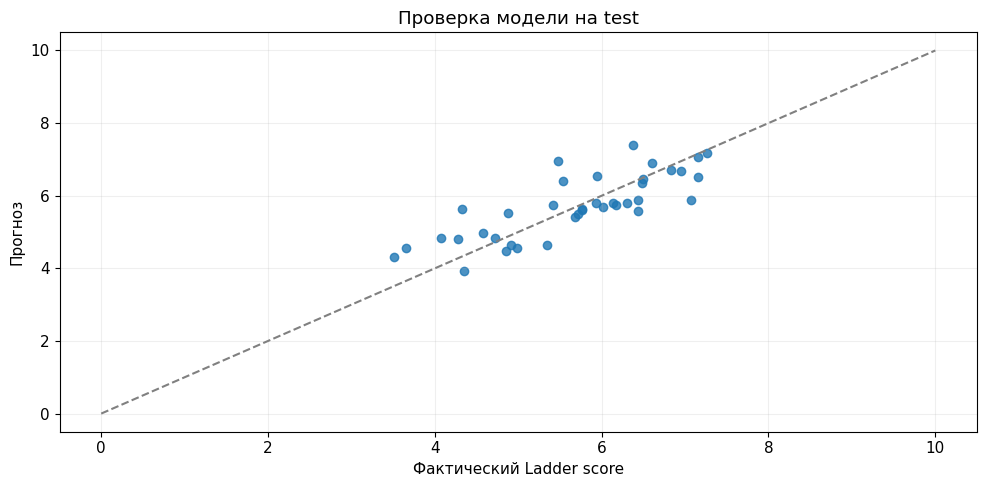

In [4]:
def train_forest(X_train, y_train, n_estimators, max_depth, min_samples_leaf, seed):
    model = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                 min_samples_leaf=min_samples_leaf, random_state=seed, n_jobs=-1)
    return model.fit(X_train, y_train)


model = train_forest(X_train, y_train, n_estimators=200, max_depth=4,
                     min_samples_leaf=2, seed=SEED)
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
rows = []
for name, estimator in [('Среднее train', baseline), ('Random Forest', model)]:
    prediction = estimator.predict(X_test)
    rows.append({'модель': name, 'RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
                 'MAE': mean_absolute_error(y_test, prediction), 'R²': r2_score(y_test, prediction)})
display(pd.DataFrame(rows).set_index('модель').round(3))
plt.scatter(y_test, model.predict(X_test), alpha=.8)
plt.plot([0, 10], [0, 10], '--', color='grey')
plt.xlabel('Фактический Ladder score'); plt.ylabel('Прогноз'); plt.title('Проверка модели на test')
plt.tight_layout(); plt.show()

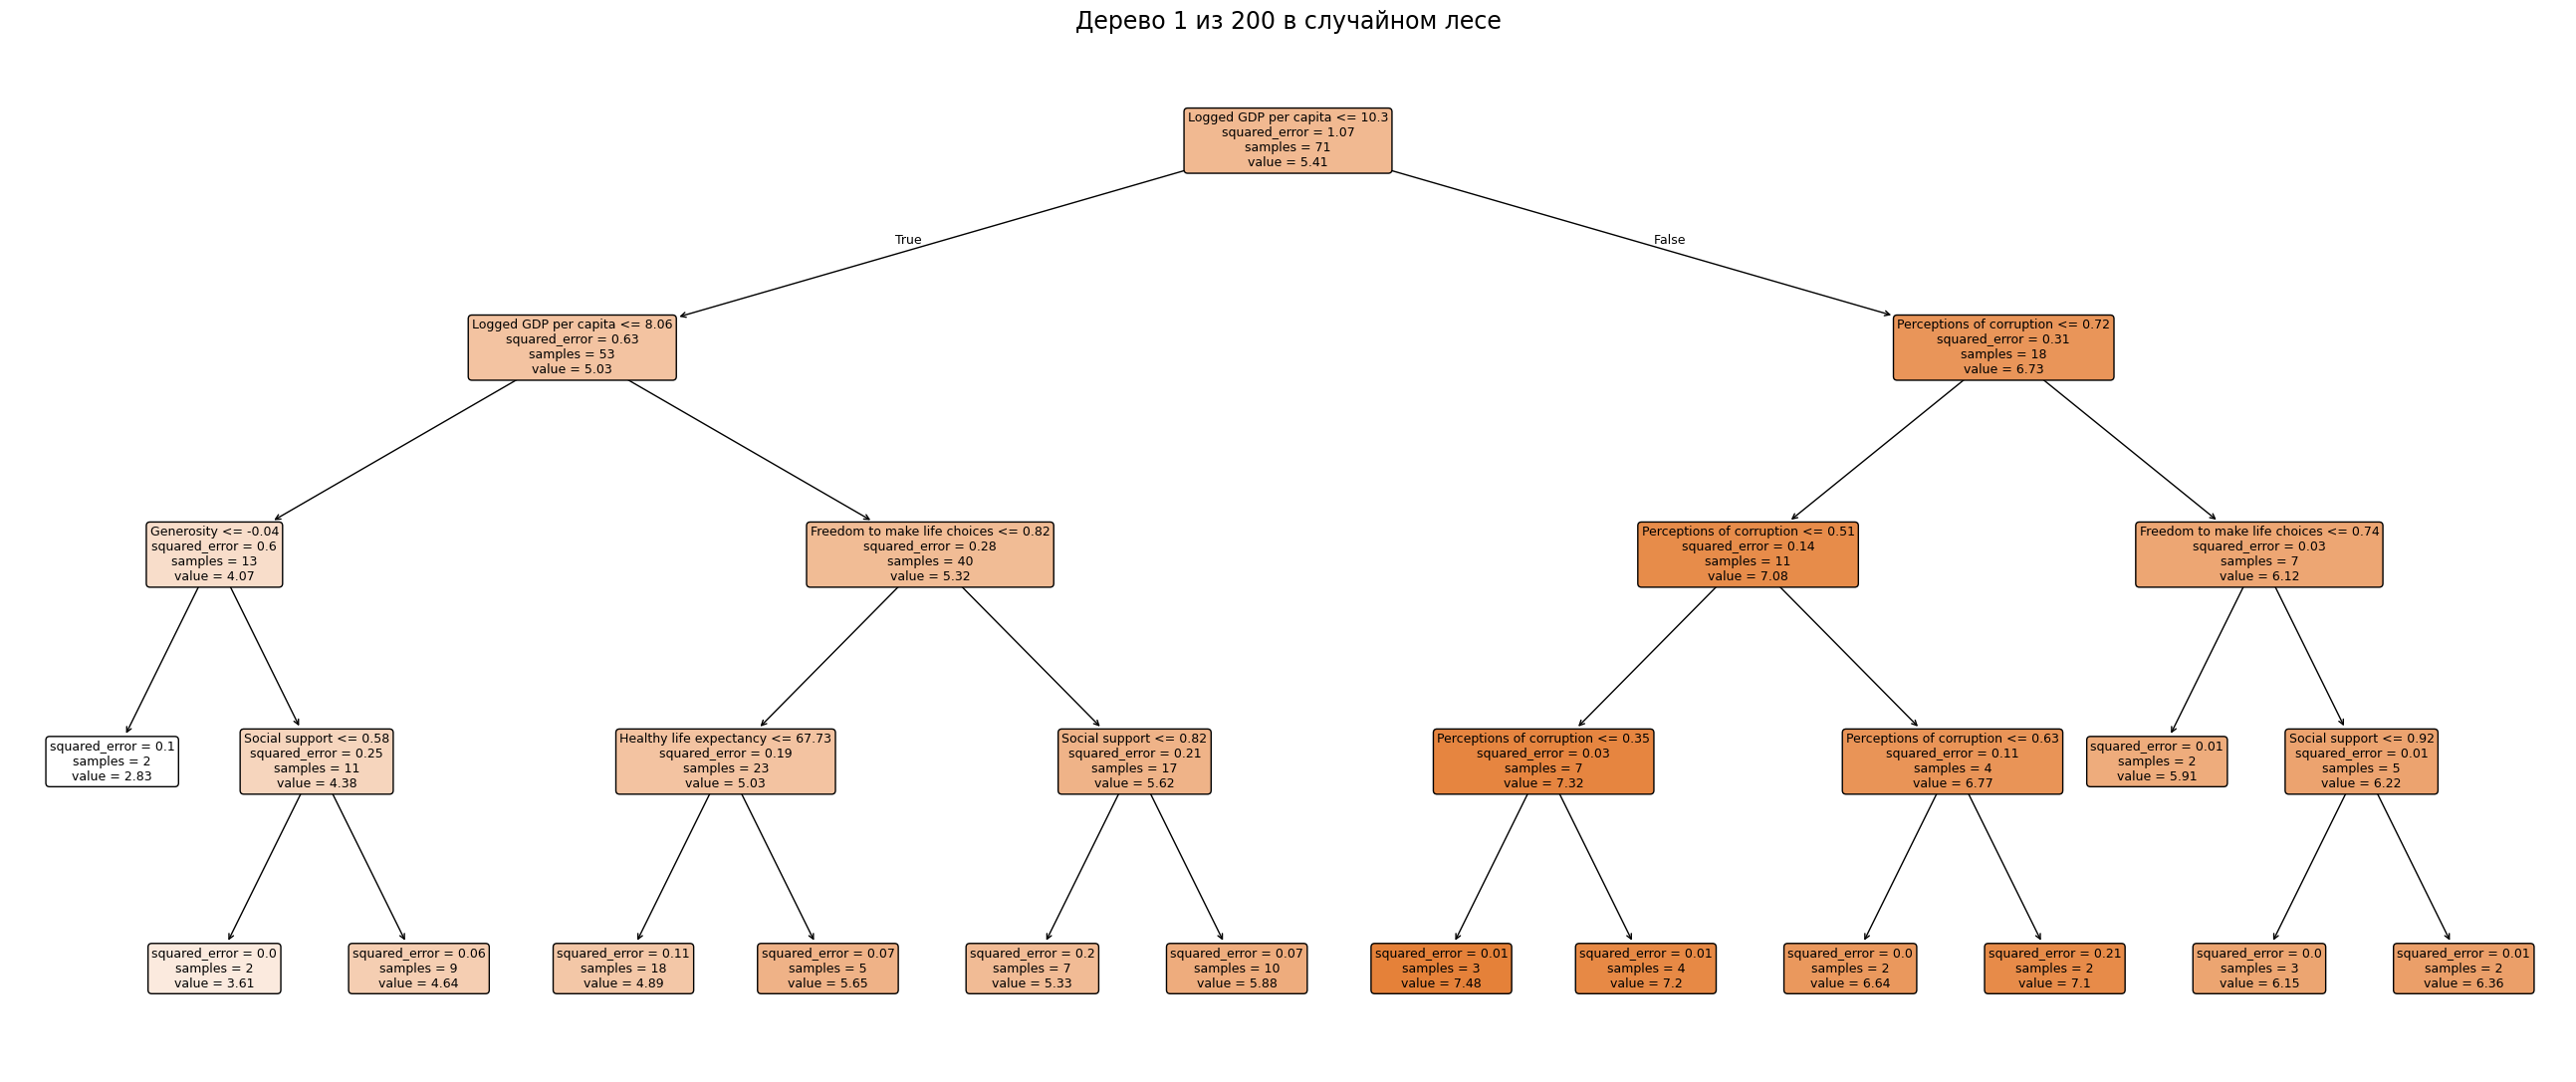

In [5]:
from sklearn.tree import plot_tree

def show_tree(forest, feature_names, tree_index=0, max_depth=None, figsize=(26, 11)):
    fig, ax = plt.subplots(figsize=figsize)
    plot_tree(forest.estimators_[tree_index], feature_names=feature_names,
              max_depth=max_depth, filled=True, rounded=True,
              impurity=True, precision=2, fontsize=9, ax=ax)
    ax.set_title(f'Дерево {tree_index + 1} из {len(forest.estimators_)} в случайном лесе', fontsize=17)
    fig.tight_layout()
    plt.show()


show_tree(model, feature_names, tree_index=0, max_depth=None, figsize=(26, 11))

## 2. Встроенная важность признаков

**Спрашивает:** «Какие признаки сильнее уменьшали ошибку в разбиениях обученных деревьев?»

Для регрессии загрязнённость узла измеряется дисперсией целевых значений. Вклад разбиения равен взвешенному уменьшению этой дисперсии; вклады признака суммируются по узлам, нормируются и усредняются по деревьям.

MDI (`feature_importances_`) не показывает знак зависимости. Она вычисляется по train и может предпочитать признаки с большим числом вариантов разбиения. Коррелирующие признаки могут делить важность. Лес целиком не становится понятным только из-за наличия такого графика.

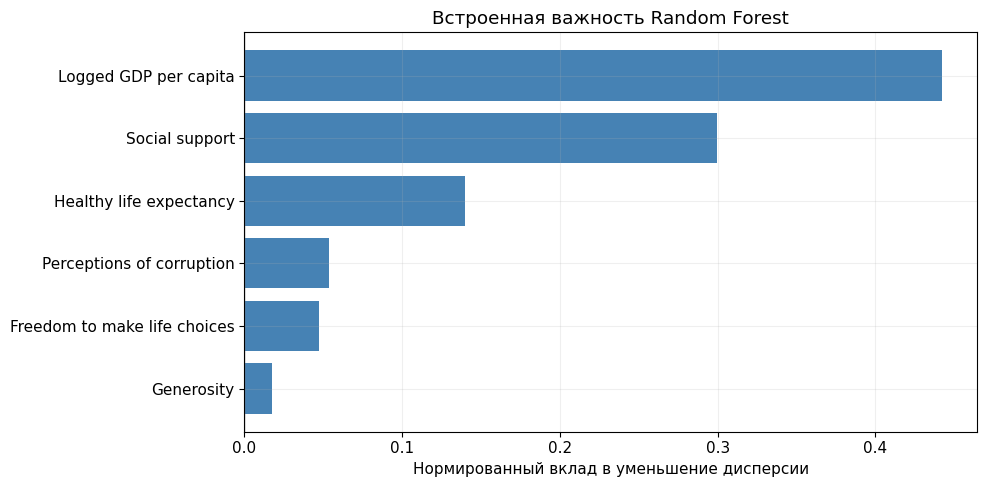

In [6]:
def plot_importance(values, title, xlabel, errors=None):
    ordered = values.sort_values()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(ordered.index, ordered.values,
            xerr=None if errors is None else errors.loc[ordered.index].values,
            color='steelblue', capsize=3)
    ax.axvline(0, color='grey', linewidth=1)
    ax.set_title(title); ax.set_xlabel(xlabel)
    fig.tight_layout(); plt.show()


mdi = pd.Series(model.feature_importances_, index=feature_names)
plot_importance(mdi, title='Встроенная важность Random Forest', xlabel='Нормированный вклад в уменьшение дисперсии')

## 3. ICE и PDP

**ICE спрашивает:** «Как изменится прогноз для этого объекта, если менять один признак, оставляя остальные фиксированными?»

**PDP спрашивает:** «Как выглядит средняя такая реакция по выбранным объектам?»

Кривые описывают модель. Подстановка значений может создавать нереалистичные комбинации, особенно при корреляции факторов. Это не оценка результата вмешательства в экономику страны. Для PDP используем `method='brute'`, чтобы средняя кривая была вычислена по тем же объектам, что и ICE.

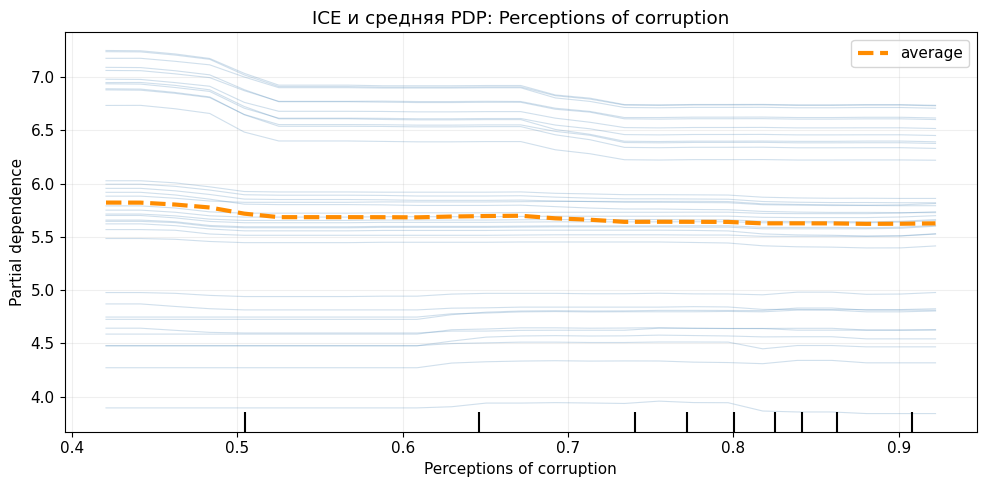

In [7]:
def plot_ice_pdp(model, X_reference, feature, grid_resolution=25, max_curves=35, seed=42):
    fig, ax = plt.subplots(figsize=(10, 5))
    PartialDependenceDisplay.from_estimator(
        model, X_reference, features=[feature], kind='both', method='brute',
        grid_resolution=grid_resolution, subsample=min(max_curves, len(X_reference)),
        random_state=seed, ax=ax,
        ice_lines_kw={'alpha': .25, 'linewidth': .8, 'color': 'steelblue'},
        pd_line_kw={'linewidth': 3, 'color': 'darkorange'},
    )
    ax.set_ylabel('Прогноз Ladder score'); ax.set_title(f'ICE и средняя PDP: {feature}')
    fig.tight_layout(); plt.show()


FEATURE = 'Perceptions of corruption'
plot_ice_pdp(model, X_test, feature=FEATURE, grid_resolution=25, max_curves=35, seed=SEED)

### Двумерная PDP

Одновременно меняем два признака, усредняя прогноз по остальным координатам выбранных объектов. Цвет соответствует прогнозу. Форма поверхности может подсказать взаимодействия, но сама по себе не является доказательством их отсутствия или наличия во всех данных.

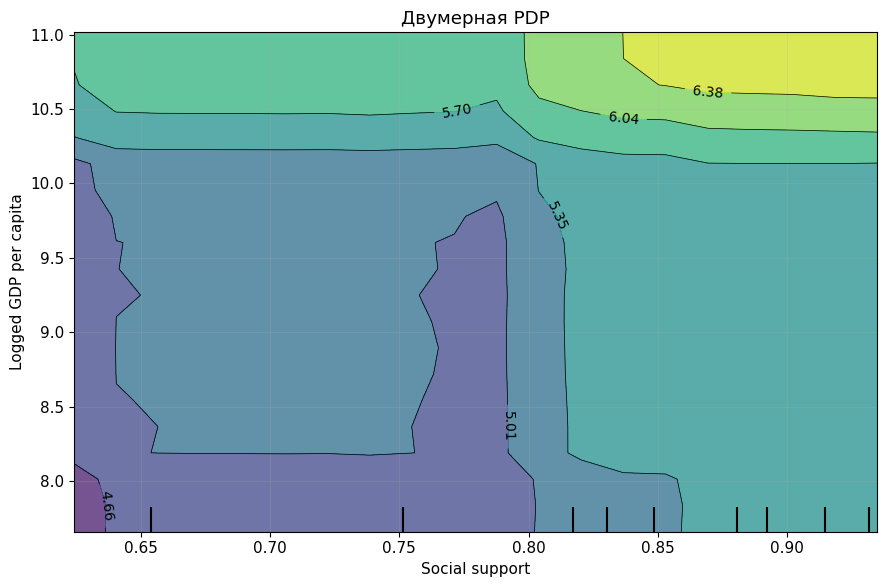

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
PartialDependenceDisplay.from_estimator(model, X_test,
    features=[('Social support', 'Logged GDP per capita')],
    kind='average', method='brute', grid_resolution=20, ax=ax)
ax.set_title('Двумерная PDP'); fig.tight_layout(); plt.show()

## 4. ALE

**Спрашивает:** «Как модель реагирует на небольшие изменения признака в областях, где действительно есть объекты?»

ALE делит значения на интервалы, оценивает локальные разности прогноза внутри каждого интервала, накапливает их и центрирует. Это уменьшает проблему экстраполяции PDP при зависимых признаках, но не превращает график в причинный эффект.

PDP ниже центрируем отдельно, чтобы сравнивать форму с ALE. Их абсолютные уровни до центрирования имеют разный смысл. При малой выборке мелкие интервалы ненадёжны; здесь используем 8 интервалов без доверительных полос.

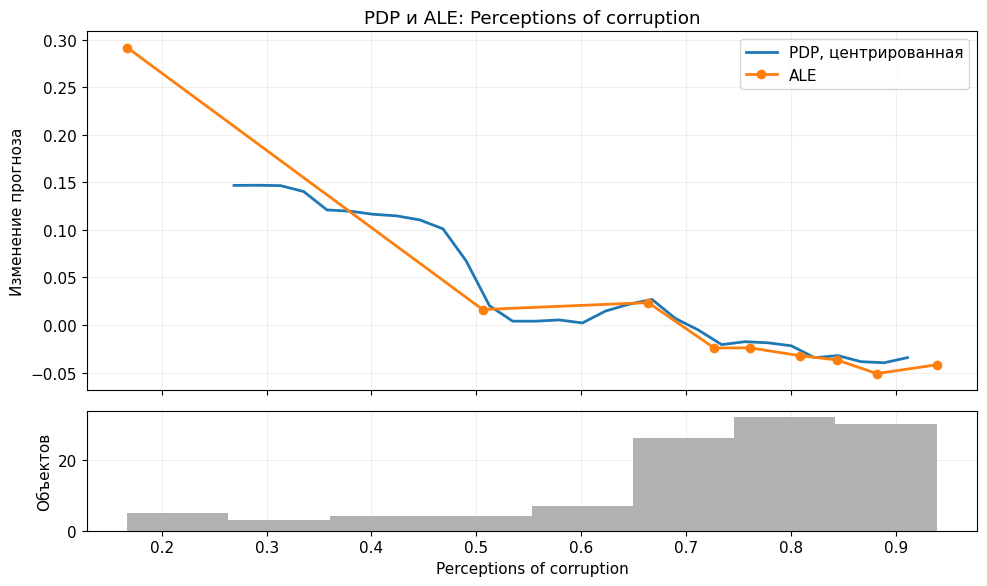

,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
Logged GDP per capita,1.00,0.80,0.85,0.43,-0.25,-0.29
Social support,0.80,1.00,0.75,0.48,-0.13,-0.20
Healthy life expectancy,0.85,0.75,1.00,0.45,-0.18,-0.33
Freedom to make life choices,0.43,0.48,0.45,1.00,0.23,-0.43
Generosity,-0.25,-0.13,-0.18,0.23,1.00,-0.13
Perceptions of corruption,-0.29,-0.20,-0.33,-0.43,-0.13,1.00


In [9]:
from sklearn.inspection import partial_dependence

def compare_pdp_ale(model, X_reference, feature, n_bins=8):
    effects = ale(X=X_reference.copy(), model=model, feature=[feature],
                  feature_type='continuous', grid_size=n_bins, include_CI=False, plot=False)
    pdp = partial_dependence(model, X_reference, [feature], method='brute', grid_resolution=30)
    grid = pdp['grid_values'][0]
    curve = pdp['average'][0]
    centered = curve - np.mean(np.interp(X_reference[feature], grid, curve))
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                             gridspec_kw={'height_ratios': [3, 1]})
    axes[0].plot(grid, centered, label='PDP, центрированная', linewidth=2)
    axes[0].plot(effects.index, effects['eff'], marker='o', label='ALE', linewidth=2)
    axes[0].set_ylabel('Изменение прогноза'); axes[0].legend()
    axes[0].set_title(f'PDP и ALE: {feature}')
    axes[1].hist(X_reference[feature], bins=n_bins, color='grey', alpha=.6)
    axes[1].set_ylabel('Объектов'); axes[1].set_xlabel(feature)
    fig.tight_layout(); plt.show()
    return effects


ale_effects = compare_pdp_ale(model, X_train, feature=FEATURE, n_bins=8)
display(X_train.corr().round(2))

## 5. Permutation importance

**Спрашивает:** «Насколько ухудшится качество, если перемешать этот признак и разрушить его связь с объектами?»

Для ошибки MSE важность равна **MSE после перестановки минус исходная MSE**. В sklearn используется разность score до и после перестановки; при `neg_mean_squared_error` это та же величина.

Считаем на test без переобучения модели. Полосы показывают стандартное отклонение по перестановкам, а не доверительный интервал качества на новых странах. При зависимых признаках модель может использовать заменяющий признак; также перестановка создаёт непривычные комбинации. После изучения test не подбираем по нему модель.

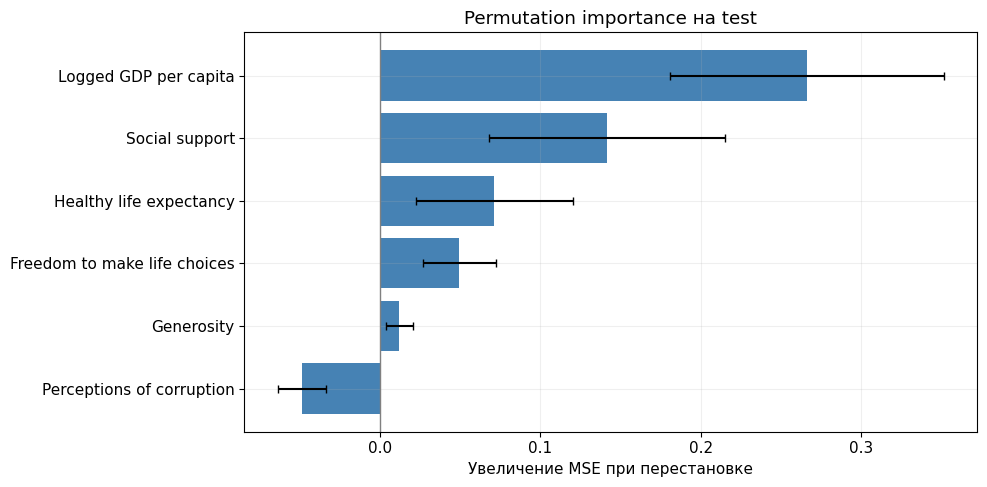

,MDI,Permutation ΔMSE
Logged GDP per capita,0.442320,0.266172
Social support,0.299449,0.141522
Healthy life expectancy,0.140100,0.071276
Freedom to make life choices,0.047208,0.049576
Generosity,0.017398,0.012142
Perceptions of corruption,0.053526,-0.048711


In [10]:
perm = permutation_importance(model, X_test, y_test,
    scoring='neg_mean_squared_error', n_repeats=30, random_state=SEED, n_jobs=1)
perm_mean = pd.Series(perm.importances_mean, index=feature_names)
perm_std = pd.Series(perm.importances_std, index=feature_names)
plot_importance(perm_mean, title='Permutation importance на test',
                xlabel='Увеличение MSE при перестановке', errors=perm_std)
display(pd.DataFrame({'MDI': mdi, 'Permutation ΔMSE': perm_mean}).sort_values('Permutation ΔMSE', ascending=False))

В сохранённом прогоне `Perceptions of corruption` имеет отрицательную permutation importance: перемешивание в среднем улучшило MSE на этой test-выборке. Это не означает, что коррупция полезна; речь о качестве использования признака конкретной моделью.

## 6. SHAP: объяснение одного прогноза

**Спрашивает:** «Как распределить отличие прогноза от базового значения между признаками?»

Для регрессии базовый прогноз и вклады выражены в баллах Ladder score. Сумма вкладов и базового значения восстанавливает прогноз модели. Используем TreeSHAP с явно заданным режимом `tree_path_dependent`: фоновое распределение задаётся обучающими статистиками проходов по деревьям. Это способ расчёта объяснения, а не основание для причинного вывода.

Выбираем страну по названию через `COUNTRY`. Эту же строку объясним SHAP и LIME. Если она находится в train, локальная иллюстрация не является независимой проверкой качества; общие метрики и глобальные SHAP-графики по-прежнему считаются на test. Положительный вклад повышает прогноз относительно базового значения, отрицательный понижает. Величина зависит от модели, фоновых данных и определения отсутствующего признака.

Страна: Russia | Выборка: train
Факт: 5.477; прогноз: 5.627; база SHAP: 5.490


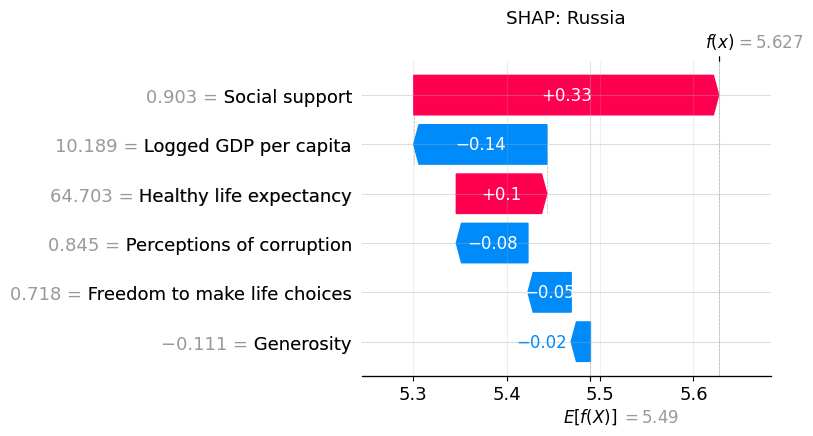

In [11]:
COUNTRY = 'Russia'
country_index = df.index[df['Country name'].eq(COUNTRY)].item()
local_X = X.loc[[country_index]]
local_target = y.loc[country_index]
country = COUNTRY
explainer = shap.TreeExplainer(model,
    feature_perturbation='tree_path_dependent', model_output='raw')
shap_values = explainer(X_test)
predictions = model.predict(X_test)
assert np.allclose(shap_values.base_values + shap_values.values.sum(axis=1), predictions, atol=1e-5)
local_shap = explainer(local_X)[0]
local_prediction = float(model.predict(local_X)[0])
assert np.isclose(local_shap.base_values + local_shap.values.sum(), local_prediction, atol=1e-5)
print('Страна:', country, '| Выборка:', 'train' if country_index in X_train.index else 'test')
print(f'Факт: {local_target:.3f}; прогноз: {local_prediction:.3f}; база SHAP: {float(local_shap.base_values):.3f}')
shap.plots.waterfall(local_shap, max_display=6, show=False)
plt.title(f'SHAP: {country}'); plt.tight_layout(); plt.show()

## 7. LIME: локальная простая модель

**Спрашивает:** «Какая простая модель приблизит поведение сложной модели рядом с этим объектом?»

LIME генерирует соседние точки, получает прогнозы леса и подгоняет локальную взвешенную линейную модель. Её коэффициенты не равны SHAP-вкладам: другие базовая точка, шкала и задача оптимизации. Показываем обе оценки прогноза и локальный R², чтобы проверить качество приближения.

Независимое возмущение координат может создавать нереалистичные страны. Даже высокий R² относится к синтетическому локальному окружению, а не доказывает правильность исходного прогноза.

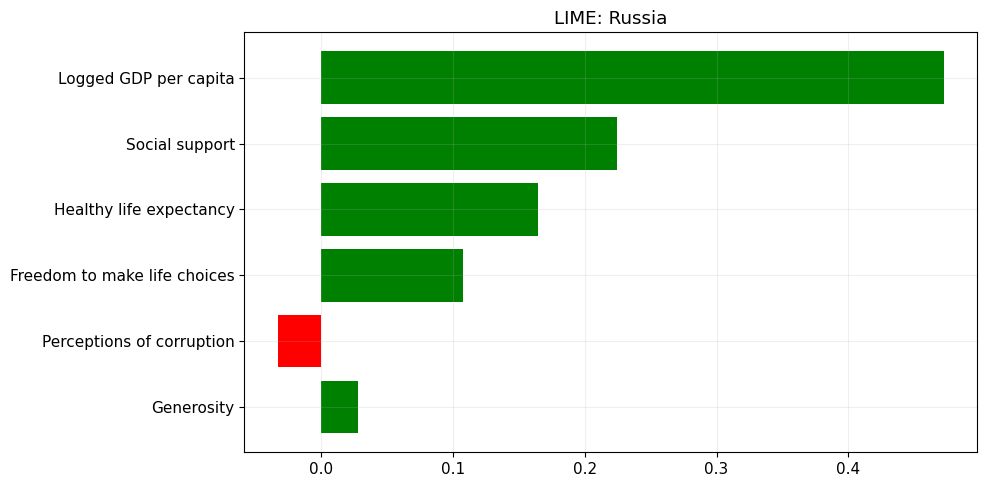

Прогноз леса              5.626970
База + сумма SHAP         5.626970
Локальный прогноз LIME    5.731357
Локальный R² LIME         0.735280
dtype: float64

In [13]:
def explain_lime(model, X_background, row, num_samples=4000, kernel_width=1.8, seed=42):
    lime_explainer = LimeTabularExplainer(
        X_background.to_numpy(), feature_names=X_background.columns.tolist(),
        mode='regression', discretize_continuous=False, sample_around_instance=True,
        kernel_width=kernel_width, random_state=seed)
    def predict_rows(values):
        return model.predict(pd.DataFrame(values, columns=X_background.columns))
    return lime_explainer.explain_instance(row.to_numpy(), predict_rows,
        num_features=X_background.shape[1], num_samples=num_samples)


row = local_X.iloc[0]
lime_exp = explain_lime(model, X_train, row, num_samples=4000, kernel_width=1.8, seed=SEED)
fig = lime_exp.as_pyplot_figure()
fig.set_size_inches(10, 5); plt.title(f'LIME: {country}'); plt.tight_layout(); plt.show()
display(pd.Series({'Прогноз леса': local_prediction,
    'База + сумма SHAP': float(local_shap.base_values + local_shap.values.sum()),
    'Локальный прогноз LIME': float(lime_exp.local_pred[0]),
    'Локальный R² LIME': lime_exp.score}))

Сравниваем прогноз леса, сумму SHAP-вкладов и локальное приближение LIME для выбранной страны. Коэффициенты LIME описывают локальные направления и не обязаны совпадать по знаку с SHAP-вкладами относительно базы.

### Устойчивость LIME

Повторим объяснение той же страны с тремя случайными зернами. Модель и объект не меняются. Различия возникают из-за выборки синтетических соседей. Не выбираем самое удобное объяснение по совпадению с ожиданиями.

In [14]:
stability = []
for seed in [7, 42, 67]:
    explanation = explain_lime(model, X_train, row, num_samples=4000, kernel_width=1.8, seed=seed)
    weights = dict(explanation.local_exp[1])
    stability.append({'seed': seed, 'local R²': explanation.score,
        **{feature: weights.get(i, 0) for i, feature in enumerate(feature_names)}})
display(pd.DataFrame(stability).set_index('seed').round(3))

,local R²,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
seed,,,,,,,
7,0.737,0.477,0.238,0.160,0.112,0.027,-0.040
42,0.735,0.472,0.225,0.165,0.107,0.028,-0.033
67,0.728,0.480,0.233,0.158,0.102,0.028,-0.035


## 8. Итоги

| Метод | Что объясняет | Что важно помнить |
|---|---|---|
| MDI | Использование признаков деревьями | Важность по train, без знака |
| ICE / PDP | Реакцию прогноза на подстановку значений | Возможны нереалистичные комбинации |
| ALE | Накопленные локальные изменения | Зависит от интервалов и покрытия данных |
| Permutation | Потерю качества после перемешивания | Коррелирующие признаки могут заменять друг друга |
| SHAP | Распределение отклонения от базы | Результат зависит от фона и предположений |
| LIME | Локальное линейное приближение | Проверяем точность и устойчивость приближения |

Вопросы: совпали ли лидеры MDI, permutation и SHAP? У какой страны прогноз далёк от факта, и что объясняет SHAP в этом случае? Почему объяснение может измениться при другом способе учёта зависимостей признаков? Можно ли из PDP заключить, что изменение фактора улучшит жизнь страны?

Объяснение модели не является объяснением причин реального явления. Ни SHAP, ни LIME не подтверждают правильность прогноза.
